In [36]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, RocCurveDisplay)

# Import your model here
import torch, torch.nn as nn

# Import train_test_split, seaborn, matplotlib
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

import itertools
import numpy as np

# Anchor the seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)


In [37]:
#Change to your model's name (used in graphs)
MODEL_NAME = "Multi-Layer Perceptron"

# Read dataset
df = pd.read_csv("../../data/CleanedLifeInsurance.csv")

# Define features and target
numeric_features = ["ENTRY AGE", "Policy Year", "BENEFIT", "Premium", "SUBSTANDARD RISK"]
categorical_features = ["PAYMENT MODE"]

X = df[numeric_features + categorical_features]
y = df["is_lapse"]

# Split data into train and test sets (keep random_state = 42 to ensure you get the same data splits every time.)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [38]:
# # Preprocess features
# # numeric: fill missing values (Premium, BENEFIT) with the median, add a column flagging
# # which values were missing, then scale. Scaling doesn't matter for tree models but doesn't hurt.
# # categorical: one-hot encode PAYMENT MODE into 0/1 columns.

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

Xt = torch.tensor(X_train, dtype=torch.float32)
yt = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
Xv = torch.tensor(X_test, dtype=torch.float32)

In [39]:
# model = nn.Sequential(
#     nn.Linear(Xt.shape[1], 64), nn.ReLU(),
#     nn.Linear(64, 32), nn.ReLU(),
#     nn.Linear(32, 1)
# )

In [40]:
# loss_fn = nn.BCEWithLogitsLoss()
# opt = torch.optim.Adam(model.parameters(), lr=1e-3)

# for epoch in range(50):
#     model.train()
#     for i in torch.randperm(len(Xt)).split(256):
#         opt.zero_grad()
#         loss_fn(model(Xt[i]), yt[i]).backward()
#         opt.step()

# model.eval()
# with torch.no_grad():
#     y_prob = torch.sigmoid(model(Xv)).squeeze().numpy()
# y_pred = (y_prob > 0.5).astype(int)

In [41]:
# # Evaluate performance
# print(f"{MODEL_NAME} Performance on Test Set:")
# print("\nAccuracy:", accuracy_score(y_test, y_pred))

# print("\nMacro F1:", f1_score(y_test, y_pred, average="macro"))

# print("\nROC-AUC:", roc_auc_score(y_test, y_prob))

# print("\nClassification Report:")
# print(classification_report(y_test, y_pred, target_names=["Not lapse", "Lapse"]))

# print("\nConfusion Matrix:")
# print(confusion_matrix(y_test, y_pred))

In [42]:

# # Graph 1: Confusion matrix heatmap
# cm = confusion_matrix(y_test, y_pred)
# cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
# class_names = ["Not lapse", "Lapse"]

In [43]:
# plt.figure(figsize=(6, 5))
# sns.heatmap(
#     cm_percent,
#     annot=True,
#     fmt=".1f",
#     cmap="Blues",
#     xticklabels=class_names,
#     yticklabels=class_names,
#     cbar_kws={"label": "% of Actual Class"}
# )
# plt.title(f"Confusion Matrix - {MODEL_NAME}")
# plt.xlabel("Predicted Class")
# plt.ylabel("Actual Class")
# plt.tight_layout()

# # Graph 2: ROC curve
# RocCurveDisplay.from_predictions(y_test, y_prob, name=MODEL_NAME, plot_chance_level=True)
# plt.title(f"ROC Curve - {MODEL_NAME}")
# plt.tight_layout()


# Neural Network Fine-Tuning Workflow

*   **1. Data Splitting (Train vs. Validation vs. Test)**
    *   **Training Set:** The data used to calculate loss and update the model's internal weights.
    *   **Validation Set:** A temporary holdout dataset used to test and compare different hyperparameter settings without exposing the model to the final test data.
    *   **Test Set:** The strictly isolated final dataset used only once at the very end to evaluate true real-world performance. 

*   **2. Grid Search (Hyperparameter Tuning)**
    *   Define a dictionary of potential settings to test (e.g., learning rates, number of hidden layers, weight decay/regularization).
    *   The script systematically builds and trains a unique model for every possible combination in that grid.

*   **3. Decision Threshold Optimization**
    *   Neural networks output a raw probability between 0 and 1. 
    *   Instead of assuming a static 0.5 cutoff for binary predictions, the script evaluates the validation probabilities across a sliding scale (e.g., 0.1 to 0.9).
    *   It selects the exact threshold that maximizes the target evaluation metric (like Macro F1), which mathematically corrects for imbalances between classes.

*   **4. Parameter Selection**
    *   The script logs the validation score for every combination.
    *   It identifies the single pairing of network architecture, optimizer settings, and probability threshold that performed the best.

*   **5. Retraining on Full Data**
    *   The training and validation sets are merged back into one complete training dataset.
    *   A completely fresh model is initialized using the winning hyperparameters and trained on this full dataset to maximize the amount of learning material.

*   **6. Final Inference and Evaluation**
    *   The fully optimized model predicts probabilities for the untouched Test Set.
    *   The optimized decision threshold is applied to convert those probabilities into final discrete classes (e.g., 0 or 1).
    *   Final performance metrics (Accuracy, ROC-AUC, Classification Report) are calculated and graphed.

# Fine Tuning

In [44]:


# 1. Split training data (80% train / 20% validation)
val_size = int(0.2 * len(Xt))
perm = torch.randperm(len(Xt))
X_tr, y_tr = Xt[perm[val_size:]], yt[perm[val_size:]]
X_va, y_va = Xt[perm[:val_size]], yt[perm[:val_size]]

# 2. Define hyperparameter search space
param_grid = {
    "lr": [1e-2, 1e-3, 5e-4],
    "weight_decay": [0.0, 1e-4],
    "h1": [64, 128],
    "h2": [32, 64]
}

best_score = -1
best_thresh = 0.5
best_params = {}

# 3. Grid Search Loop
for lr, wd, h1, h2 in itertools.product(
    param_grid["lr"], param_grid["weight_decay"], param_grid["h1"], param_grid["h2"]
):
    # Initialize network with current grid parameters
    net = nn.Sequential(
        nn.Linear(Xt.shape[1], h1), nn.ReLU(),
        nn.Linear(h1, h2), nn.ReLU(),
        nn.Linear(h2, 1)
    )
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.BCEWithLogitsLoss()

    # Train for 30 epochs
    net.train()
    for epoch in range(30):
        for idx in torch.randperm(len(X_tr)).split(256):
            opt.zero_grad()
            loss_fn(net(X_tr[idx]), y_tr[idx]).backward()
            opt.step()

    # Predict probabilities on validation set
    net.eval()
    with torch.no_grad():
        val_probs = torch.sigmoid(net(X_va)).squeeze().numpy()
    
    y_va_np = y_va.squeeze().numpy()

    # Search for the optimal decision threshold (instead of hardcoding 0.5)
    thresholds = np.linspace(0.2, 0.8, 61)
    scores = [f1_score(y_va_np, (val_probs > t).astype(int), average="macro") for t in thresholds]
    
    max_f1_for_params = max(scores)
    optimal_t_for_params = thresholds[np.argmax(scores)]

    # Update best metrics if this combination is better
    if max_f1_for_params > best_score:
        best_score = max_f1_for_params
        best_thresh = optimal_t_for_params
        best_params = {"lr": lr, "weight_decay": wd, "h1": h1, "h2": h2}

print(f"Best Params: {best_params}")
print(f"Best Val Macro F1: {best_score:.4f} (at Threshold: {best_thresh:.2f})")

# 4. Retrain optimal model on the ENTIRE training dataset (Xt)
h1, h2 = best_params["h1"], best_params["h2"]
model = nn.Sequential(
    nn.Linear(Xt.shape[1], h1), nn.ReLU(),
    nn.Linear(h1, h2), nn.ReLU(),
    nn.Linear(h2, 1)
)
opt = torch.optim.Adam(model.parameters(), lr=best_params["lr"], weight_decay=best_params["weight_decay"])
loss_fn = nn.BCEWithLogitsLoss()

model.train()
for epoch in range(50):
    for idx in torch.randperm(len(Xt)).split(256):
        opt.zero_grad()
        loss_fn(model(Xt[idx]), yt[idx])

Best Params: {'lr': 0.01, 'weight_decay': 0.0, 'h1': 128, 'h2': 64}
Best Val Macro F1: 0.6668 (at Threshold: 0.58)


# Final Validation

In [47]:
# Retrain model using the best parameters from the grid search
model = nn.Sequential(
    nn.Linear(Xt.shape[1], 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 1)
)
opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0)
loss_fn = nn.BCEWithLogitsLoss()

model.train()
for epoch in range(50):
    for idx in torch.randperm(len(Xt)).split(256):
        opt.zero_grad()
        loss_fn(model(Xt[idx]), yt[idx]).backward()
        opt.step()

# Generate new test set predictions using the optimized threshold (0.58)
model.eval()
with torch.no_grad():
    y_prob = torch.sigmoid(model(Xv)).squeeze().numpy()

# Apply the 0.53 threshold found during tuning
y_pred = (y_prob > 0.58).astype(int)

Multi-Layer Perceptron Performance on Test Set:

Accuracy: 0.669460012933822

Macro F1: 0.6618678854574174

ROC-AUC: 0.7268896723763152

Classification Report:
              precision    recall  f1-score   support

   Not lapse       0.68      0.56      0.61     17339
       Lapse       0.66      0.77      0.71     19773

    accuracy                           0.67     37112
   macro avg       0.67      0.66      0.66     37112
weighted avg       0.67      0.67      0.67     37112


Confusion Matrix:
[[ 9642  7697]
 [ 4570 15203]]


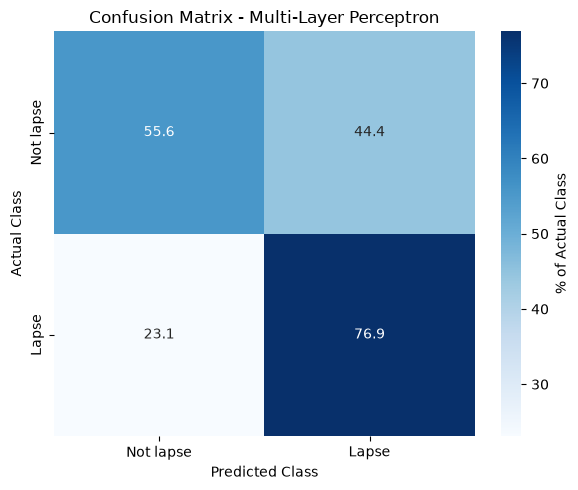

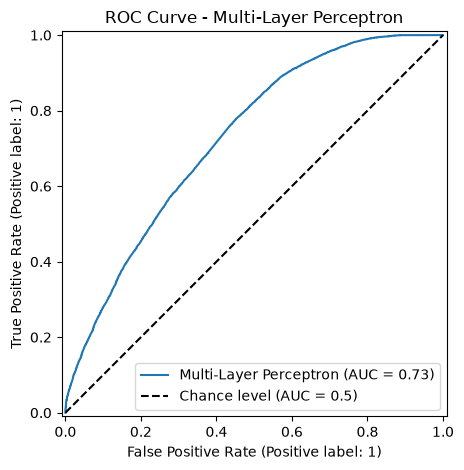

In [48]:
# Evaluate performance
print(f"{MODEL_NAME} Performance on Test Set:")
print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nMacro F1:", f1_score(y_test, y_pred, average="macro"))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Not lapse", "Lapse"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Graph 1: Confusion Matrix heatmap
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
class_names = ["Not lapse", "Lapse"]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "% of Actual Class"}
)
plt.title(f"Confusion Matrix - {MODEL_NAME}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# Graph 2: ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob, name=MODEL_NAME, plot_chance_level=True)
plt.title(f"ROC Curve - {MODEL_NAME}")
plt.tight_layout()
plt.show()